# Utilities

## Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import re, string, joblib, umap, time, pickle
import numpy as np
from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

# Visualization
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# Hierarchical clustering
from fastcluster import linkage
from scipy.cluster.hierarchy import dendrogram, fcluster
from scipy.spatial.distance import pdist

# Words cloud
from wordcloud import WordCloud

## Functions

In [2]:
# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    plt.show()

# Load data

In [3]:
data = pd.read_csv('../data/input/api/data_filtered.csv')
data.shape

(4340, 7)

In [4]:
df = pd.read_csv('../data/input/api/data_cleaned.csv')
df.shape

(1000, 4)

In [5]:
df_vectorized = pd.read_csv('../data/output/df_vectorized.csv')
X = df_vectorized.values
X.shape

(1000, 6940)

In [6]:
words2remove = []

In [7]:
vectorizer = joblib.load('../models/vectorizer.pkl')
words = vectorizer.get_feature_names_out()

Dimensionality reduction

Keep 95% of explained variance

In [8]:
# explained_variance_ratio_goal = 0.8
# pca = PCA(n_components=explained_variance_ratio_goal)
# pca.fit(df_vectorized)
# n_components = pca.n_components_
# n_components

In [9]:
X_original = X.copy()
df_vectorized_original = df_vectorized.copy()

# # X = PCA(n_components=n_components).fit_transform(X) # Specify number of components
# X = pca.transform(X) # Use fitted PCA with 95% of explained variance
# df_vectorized = pd.DataFrame(X)

# # Normalize
# X = X / np.linalg.norm(X, axis=1, keepdims=True)
# df_vectorized = pd.DataFrame(X)

In [10]:
X_original.shape

(1000, 6940)

# KNN search

In [11]:
n_neighbors = 100
knn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine', algorithm='brute').fit(X)

# Query text

# query_text = "reinforcement learning control modular multilevel matrix converter"
# query_text = "reinforcement learning control modular power converter"
# query_text = "physics informed reinforcement learning"
# query_text = "reinforcement learning"
query_text = "The artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks in power converters."
# query_text = "Control strategy, closed loop control, nested control, submodules, capacitor voltage, circulating currents, common mode voltage, voltage control, current control, energy control, power control, balancing, model predictive control, proportional integral controller, multi input multi output, modeling, total energy balance, cluster capacitor energy balance, intercluster energy balance, low frequency oscillation mitigation."
print(query_text)

# Preprocessing
query_text = [preprocess_text(query_text, words2remove)]
print(query_text)

# Vectorize
query_text_vec = vectorizer.transform(query_text).toarray()

# Dimensionality reduction
# query_text_vec = pca.transform(query_text_vec)

print(query_text_vec)

# Calculate KNNs
knn_distances, knn_idxs = knn.kneighbors(query_text_vec.reshape(1, -1))

for i, knn_idx in enumerate(knn_idxs[0]):
    print(i)
    print(knn_idx)
    display(f"Neighbor {i+1}:")
    display(f"Title: {data['title'][knn_idx]}")
    display(f"Abstract: {data['abstract'][knn_idx]}")
    display(f"Abstract: {data['html_url'][knn_idx]}")    
    print("-"*40)

The artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks in power converters.
['artificial intelligence deep learning imitation learning reinforcement learning neural network power converter']
[[0. 0. 0. ... 0. 0. 0.]]
0
982


'Neighbor 1:'

'Title: an integrated conversion system and charge balance control strategy for phev based on mmmc'

'Abstract: this paper proposes a plug in hybrid electric vehicle phev integrated conversion system which is based on modular multilevel matrix converter mmmc the proposed system could both realize motor drive and battery power management without additional charging circuit to control this system the charging control strategy from external power supply is studied by establishing the small signal model and analyzing the power relationship between different parts a balanced charging control strategy by adjusting the battery states of charge soc of each phase bridge arm and the sub module is proposed the core of which is the mmmc bridge arm current control strategy the experiments run on the rtlab hardware in the loop simulation experiment platform and the results verify the feasibility and effectiveness of the proposed soc balanced charge control strategy'

'Abstract: https://ieeexplore.ieee.org/document/8994392/'

...

'Neighbor 100:'

'Title: an adaptive modelling of neuro fuzzy and craziness pso algorithm for dc fault protection system'

'Abstract: this study makes use of pso and crpso based two unique optimization methodologies the process of well portions of the dc system must not be suggestively disrupted by a dc fault on a single division around dc circuit breakers dccbs like power driven types have low costs and power losses but because of their continued opening times they have been careful unsuitable for dc fault separation in the system the combination of switching processes and changing capacitor voltages of the sub modules in a modular multilevel converter mmc source second and other even order harmonics in the circulating currents additional power loss increased current strain on power components and even changeableness during transients will all result from these harmonic currents various case studies that involve both dc and ac problems are established the strategic control approach is validated by simulation results on a three phase grid connected mmc high voltage dc system which used sophisticated algori

'Abstract: https://ieeexplore.ieee.org/document/10053557/'

----------------------------------------


In [12]:
# import json

# # Save the index to a JSON file
# with open('../data/output/knn_indices.json', 'w') as f:
#     json.dump(knn_idxs[0].tolist(), f)

# Dimensionality reduction

### PCA

In [13]:
# # PCA 2D
# X_pca_2d = PCA(n_components=2).fit_transform(df_vectorized)
# df['pca2d_1'] = X_pca_2d[:, 0]
# df['pca2d_2'] = X_pca_2d[:, 1]

# # PCA 3D
# X_pca_3d = PCA(n_components=3).fit_transform(df_vectorized)
# df['pca3d_1'] = X_pca_3d[:, 0]
# df['pca3d_2'] = X_pca_3d[:, 1]
# df['pca3d_3'] = X_pca_3d[:, 2]

# # Graficar
# colors = np.ones(len(df))  # Color base
# colors_knn = np.zeros(len(df))  # Color para los KNN
# colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

# fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
#                     specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# # Puntos normales (fondo)
# fig.add_trace(
#     go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
#                marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                text=data['title'],
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos resaltados (delante)
# fig.add_trace(
#     go.Scatter(x=df.loc[knn_idxs[0], 'pca2d_1'], 
#                y=df.loc[knn_idxs[0], 'pca2d_2'], 
#                mode='markers',
#                marker=dict(color='red', size=5, opacity=1), 
#                text=data.loc[knn_idxs[0], 'title'], 
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos normales en 3D (fondo)
# fig.add_trace(
#     go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
#                  marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                  text=data['title'],
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# # Puntos resaltados en 3D (delante)
# fig.add_trace(
#     go.Scatter3d(x=df.loc[knn_idxs[0], 'pca3d_1'], 
#                  y=df.loc[knn_idxs[0], 'pca3d_2'], 
#                  z=df.loc[knn_idxs[0], 'pca3d_3'], 
#                  mode='markers',
#                  marker=dict(color='red', size=5, opacity=1), 
#                  text=data.loc[knn_idxs[0], 'title'], 
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
# fig.show()

### UMAP

In [14]:
# n_neighbors = 200
# n_neighbors = int(len(df) / k)

# n_neighbors = 200
n_neighbors = 50 # 6.5x minutos, resultado: vision mas global, no se distinguen tanto los clusters
# n_neighbors = 20 # 2.5x minutos, resultado: no se distinguen los clusters
# n_neighbors = 10 # 1.5x minutos, resultado: puntos muy juntos, se distinguen los clusters
# n_neighbors = 5 # x minutos, resultado: se distinguen bien los clusters, se ven un poco desconectados

min_dist = 0

# UMAP 2D
reducer_2d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=0, metric='cosine')
embedding_2d = reducer_2d.fit_transform(df_vectorized)
df['umap2d_1'] = embedding_2d[:, 0]
df['umap2d_2'] = embedding_2d[:, 1]

# UMAP 3D
reducer_3d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=3, random_state=0, metric='cosine')
embedding_3d = reducer_3d.fit_transform(df_vectorized)
df['umap3d_1'] = embedding_3d[:, 0]
df['umap3d_2'] = embedding_3d[:, 1]
df['umap3d_3'] = embedding_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[knn_idxs[0], 'umap2d_1'], 
               y=df.loc[knn_idxs[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[knn_idxs[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[knn_idxs[0], 'umap3d_1'],
                 y=df.loc[knn_idxs[0], 'umap3d_2'],
                 z=df.loc[knn_idxs[0], 'umap3d_3'],
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[knn_idxs[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## Plot KNN

In [15]:
reduced_zero = reducer_2d.transform(np.zeros(df_vectorized.shape[1]).reshape(1, -1))
reduced_knn = reducer_2d.transform(df_vectorized.iloc[knn_idxs[0]])
reduced_query = reducer_2d.transform(query_text_vec)

knn_distances = knn_distances.flatten()
reduced_knn.shape, reduced_query.shape, knn_distances.shape, reduced_zero

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



((100, 2), (1, 2), (100,), array([[9.348254, 9.203281]], dtype=float32))

In [16]:
knn_distances = knn_distances[::-1]

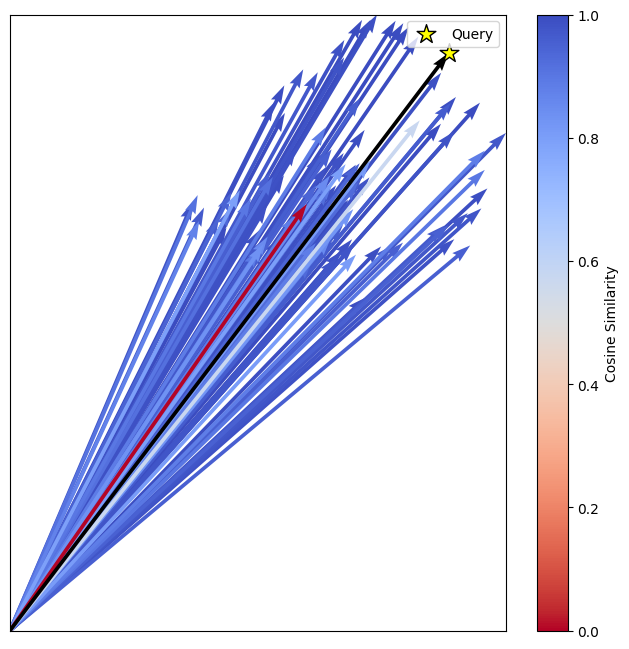

In [17]:
# Asegúrate de que las distancias estén normalizadas entre 0 y 1
exp = 1
knn_distances_normalized = (knn_distances**exp - min(knn_distances**exp)) / (max(knn_distances**exp) - min(knn_distances**exp))

# Graficar
plt.figure(figsize=(8, 8))

# Crear un mapa de colores para las distancias normalizadas
norm = plt.Normalize(vmin=0, vmax=1)  # Normalización de las distancias
sm = plt.cm.ScalarMappable(cmap="coolwarm_r", norm=norm)  # Invertir el colormap con "coolwarm_r"
sm.set_array([])  # Necesario para que la barra de colores funcione

# 2. Graficar los vectores de los vecinos más cercanos (KNN)
for i in range(reduced_knn.shape[0]):
    knn_point = reduced_knn[i]
    color = sm.to_rgba(knn_distances_normalized[i])  # Obtener el color correspondiente a la distancia
    plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], knn_point[0], knn_point[1], angles='xy', scale_units='xy', scale=1, color=color)

# 1. Graficar el vector de consulta (query vector)
query_point = reduced_query[0]
plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], query_point[0], query_point[1], angles='xy', scale_units='xy', scale=1, color='black')
# Añadir una estrella para el vector de consulta (usamos plt.scatter)
plt.scatter(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 1]+query_point[1], color='yellow', s=200, marker='*', label='Query', edgecolors='black')

# Configuración del gráfico
# plt.gca().set_aspect('equal', adjustable='box')
# plt.title('Query Vector and KNN Vectors')
plt.autoscale(True)
# plt.xlabel('umap2d_1')
# plt.ylabel('umap2d_2')
plt.xticks([])
plt.yticks([])
plt.xlim([min(reduced_zero[0, 0], reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].min()), max(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].max())])
plt.ylim([min(reduced_zero[0, 1], reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].min()), max(reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].max())])
plt.legend()
plt.colorbar(sm, label='Cosine Similarity', ax=plt.gca())
plt.savefig('../data/output/knn.pdf', format='pdf')
plt.show()


# Clustering

## Hierarchical

In [18]:
# methods = ['single', 'complete', 'average', 'weighted', 'centroid', 'ward']
# metrics = ['braycurtis', 'canberra', 'chebyshev', 'cityblock', 'correlation', 'cosine', 'dice', 'euclidean', 'hamming', 'jaccard', 'jensenshannon', 'kulczynski1', 'mahalanobis', 'matching', 'minkowski', 'rogerstanimoto', 'russellrao', 'seuclidean', 'sokalmichener', 'sokalsneath', 'sqeuclidean', 'yule']

methods = ['average', 'complete', 'weighted', 'ward']
metrics = ['cosine', 'jensenshannon', 'correlation']

method = 'ward'
metric = 'cosine'

In [19]:
# Create hierarchical clustering with provided distance matrix
Z = linkage(X, method=method, metric=metric)

# Save clustering
joblib.dump(Z, '../data/output/hierarchical_cluster_Z.joblib')

['../data/output/hierarchical_cluster_Z.joblib']

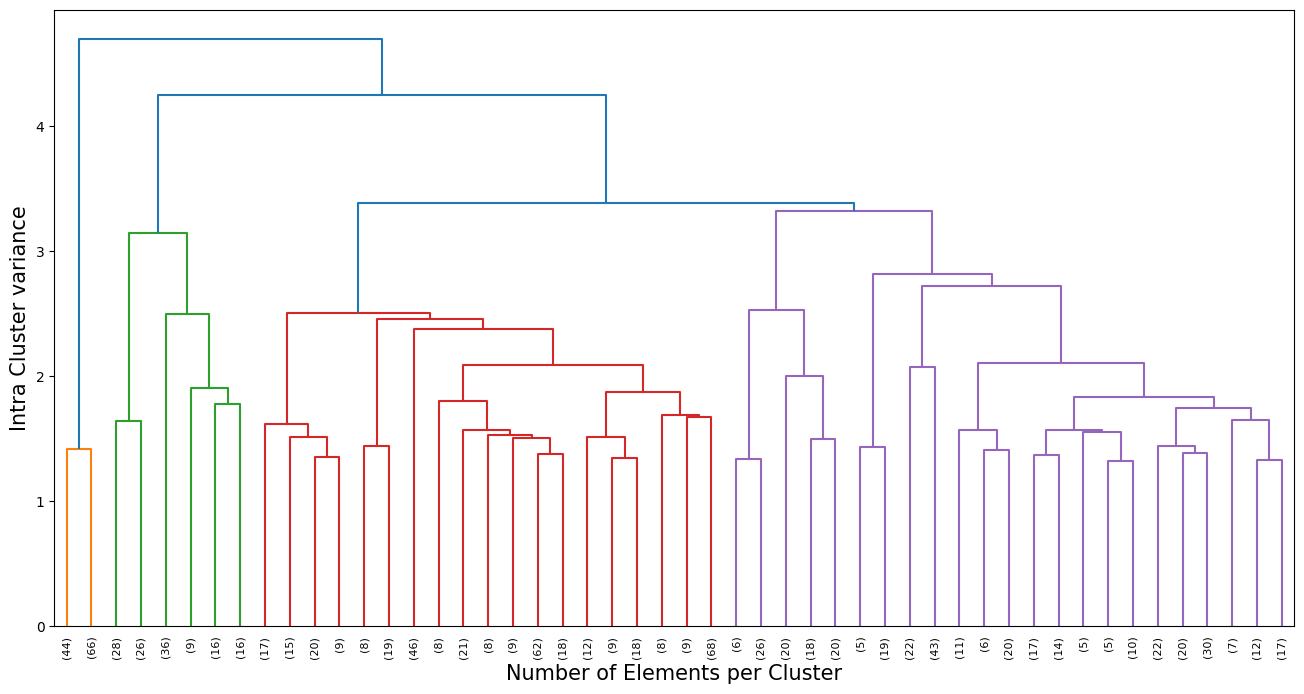

In [20]:
# Load hierarchical clustering
Z = joblib.load('../data/output/hierarchical_cluster_Z.joblib')

# Plot
plt.figure(figsize=(16, 8))
# plt.title("Hierarchical clustering dendrogram")
# dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=4.96787729660)
dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=3.3553076382448)
plt.ylabel('Intra Cluster variance', size=15)
plt.xlabel('Number of Elements per Cluster', size=15)
plt.savefig('../data/output/dendrogram.pdf', format='pdf')
plt.show()

In [21]:
# Extract threshold distances for each number of clusters
def get_threshold_distances(Z, k):
    # Extract distances from linkage matrix Z (third column)
    distances = np.sort(Z[:, 2])
    
    # La distancia umbral es la (n-k)-ésima distancia en el dendrograma
    n = Z.shape[0] + 1
    if k >= n:
        return 0  # Si k es igual o mayor al número de muestras, la distancia es mínima
    
    threshold_distance = distances[-(k-1)]
    return threshold_distance

# Rango de clusters deseado
cluster_range = range(3, 51)

# Diccionario para almacenar las distancias umbrales para cada número de clusters
threshold_distances = {k: get_threshold_distances(Z, k) for k in cluster_range}

# Mostrar las distancias umbrales para cada número de clusters
display(threshold_distances)


{3: 4.245767927725482,
 4: 3.386044068947491,
 5: 3.3211388434772413,
 6: 3.1383790439481296,
 7: 2.8170647353605864,
 8: 2.720604013546638,
 9: 2.527153901820756,
 10: 2.505459731819126,
 11: 2.4903183871529593,
 12: 2.4524347199085383,
 13: 2.37578000573787,
 14: 2.1057115927958154,
 15: 2.0826503173779463,
 16: 2.069773202012821,
 17: 1.9998847912828233,
 18: 1.8991717210243335,
 19: 1.8681765453694843,
 20: 1.8298166313714732,
 21: 1.7970647613122421,
 22: 1.7770015578166432,
 23: 1.7398452150557837,
 24: 1.6849616711008903,
 25: 1.672745579527525,
 26: 1.645809495173942,
 27: 1.6371333764297689,
 28: 1.6152900392590366,
 29: 1.568856569334345,
 30: 1.5656925055053823,
 31: 1.5634138768653787,
 32: 1.5477004711033282,
 33: 1.52514269711501,
 34: 1.5100059623115247,
 35: 1.5098988845809809,
 36: 1.5003140052981436,
 37: 1.4953029838589866,
 38: 1.440693748200265,
 39: 1.4377490232139383,
 40: 1.4325002789297434,
 41: 1.4129834811944701,
 42: 1.4044935650851214,
 43: 1.38164390964733

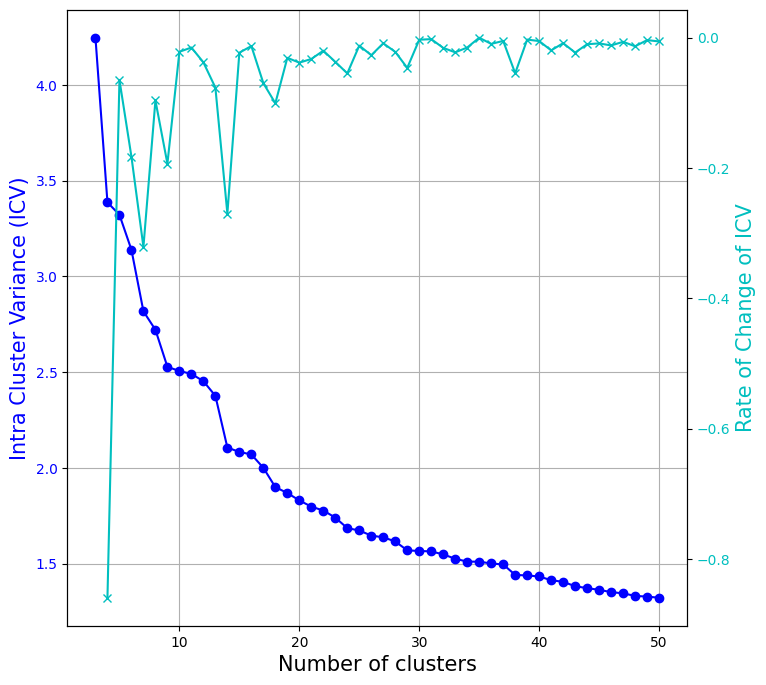

In [22]:
k_range = np.array(list(threshold_distances.keys()))
distances = np.array(list(threshold_distances.values()))
distances_dff = np.diff(distances)

# Create figure
fig, ax1 = plt.subplots(figsize=(8, 8))

# Plot threshold distances
ax1.plot(k_range, distances, marker='o', color='b', label='Threshold Distance')
ax1.set_xlabel('Number of clusters', size=15)
ax1.set_ylabel('Intra Cluster Variance (ICV)', color='b', size=15)
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True)

# Plot rate of change of threshold distances
ax2 = ax1.twinx()
ax2.plot(k_range[1:], distances_dff, marker='x', color='c', label='Rate of Change of Threshold Distance')
ax2.set_ylabel('Rate of Change of ICV', color='c', size=15)
ax2.tick_params(axis='y', labelcolor='c')

# Show plot
# plt.title('Threshold Distance and Rate of Change')
plt.savefig('../data/output/elbow_method_hierarchical_clustering.pdf', format='pdf')
plt.show()

In [23]:
# # Tune threshold for level selection for hierarchical conceptual map
# k_list_concpetual_map = k_range[np.where(distances_dff < -0.5)]
# k_list_concpetual_map

In [24]:
# df_cluster = pd.DataFrame()

# df_cluster['clusters_1'] = 0

# for k in k_list_concpetual_map:
#     clusters_HC = fcluster(Z, k, criterion='maxclust') - 1
#     df_cluster[f'clusters_{k}'] = clusters_HC

# df_cluster['clusters_1'] = 0

# df_cluster

In [25]:
# for col_idx, n_clusters in enumerate(df_cluster.columns):
#     for cluster in df_cluster[n_clusters].sort_values().unique():

#         df_topic = df_vectorized_original[df_cluster[n_clusters] == cluster]
#         centroid_words = summarize(df_topic, 5)
#         print(f'Cluster {cluster} ({df_topic.shape[0]}): {centroid_words}')

#         print(f' |---- Cluster {0}')
#     print('-'*100)

Elegir cantidad de tópicos

In [26]:
k = 5
clusters = list(range(k))
print(clusters)

[0, 1, 2, 3, 4]


In [27]:
# Asignar el cluster correspondiente
df['cluster_HC'] = fcluster(Z, k, criterion='maxclust') - 1
print(sorted(df['cluster_HC'].unique()))
df["cluster_HC"].value_counts()

[0, 1, 2, 3, 4]


cluster_HC
2    384
4    285
1    131
0    110
3     90
Name: count, dtype: int64

## Kmeans

### Metodo del codo

In [28]:
# # Listas para almacenar la inercia y el Silhouette Score de cada k
# inertia = []
# silhouette_scores = []

# # Rango de k para probar
# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Calcular la inercia y el Silhouette Score para cada valor de k
# for k_value in k_range:
#     print(f"Comenzando KMeans para k={k_value}")
#     tic = time.time()

#     kmeans = KMeans(n_clusters=k_value, random_state=0, n_init=100, init='k-means++', max_iter=100)
#     kmeans.fit(X)
    
#     # Almacenar la inercia
#     inertia.append(kmeans.inertia_)
    
#     # Calcular el Silhouette Score y almacenarlo
#     score = silhouette_score(X, kmeans.labels_)
#     silhouette_scores.append(score)
    
                                
#     toc = time.time()
#     print(f"Completado en {toc - tic:.2f} segundos\n")

# # Guardar
# with open('data/output/kmeans_metrics.pkl', 'wb') as f:
#     pickle.dump({'inertia': inertia, 'silhouette_scores': silhouette_scores}, f)

# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Cargar
# with open('data/output/kmeans_metrics.pkl', 'rb') as f:
#     metrics = pickle.load(f)
# inertia = metrics['inertia']
# silhouette_scores = metrics['silhouette_scores']

# # Calcular la tasa de cambio para la inercia y el Silhouette Score
# delta_inertia = np.diff(inertia)
# delta_silhouette = np.diff(silhouette_scores)

# # Crear una figura con dos subgráficos (lado a lado)
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# # Graficar la inercia en el primer subgráfico (izquierda)
# ax1.plot(k_range, inertia, marker='o', color='b', label='Inercia')
# ax1.set_xlabel('Número de clusters (k)')
# ax1.set_ylabel('Inercia', color='b')
# ax1.tick_params(axis='y', labelcolor='b')

# # Graficar la tasa de cambio de la inercia en el eje y derecho
# ax1_twin = ax1.twinx()
# ax1_twin.plot(k_range[1:], delta_inertia, marker='x', color='c', label='Tasa de cambio de Inercia')
# ax1_twin.set_ylabel('Tasa de cambio de Inercia', color='c')
# ax1_twin.tick_params(axis='y', labelcolor='c')

# # Título y leyenda para el primer gráfico
# ax1.set_title('Inercia y Tasa de Cambio de Inercia')
# # ax1.legend(loc='best')

# # Graficar el Silhouette Score en el segundo subgráfico (derecha)
# ax2.plot(k_range, silhouette_scores, marker='o', color='g', label='Silhouette Score')
# ax2.set_xlabel('Número de clusters (k)')
# ax2.set_ylabel('Silhouette Score', color='g')
# ax2.tick_params(axis='y', labelcolor='g')

# # Graficar la tasa de cambio del Silhouette Score en el eje y derecho
# ax2_twin = ax2.twinx()
# ax2_twin.plot(k_range[1:], delta_silhouette, marker='x', color='y', label='Tasa de cambio de Silhouette Score')
# ax2_twin.set_ylabel('Tasa de cambio de Silhouette Score', color='y')
# ax2_twin.tick_params(axis='y', labelcolor='y')

# # Título y leyenda para el segundo gráfico
# ax2.set_title('Silhouette Score y Tasa de Cambio de Silhouette Score')
# # ax2.legend(loc='best')

# # Mostrar el gráfico
# plt.tight_layout()  # Ajusta el espacio entre los subgráficos
# plt.show()

### Clustering final

In [29]:
# kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100).fit(X)
# df["cluster_KM"] = kmeans.predict(X)

# print(sorted(df['cluster_KM'].unique()))
# df["cluster_KM"].value_counts()

Clasificación de un texto

In [30]:
# predicted_cluster = kmeans.predict(topico_vec)
# print(predicted_cluster)

## Results

In [31]:
# Pintar los KNN del topico consultado
# df.loc[indices_knn[0], "cluster_HC"] = -1
# df.loc[indices_knn[0], "cluster_KM"] = -1

Choose clustering type:
* cluster_HC
* cluster_KM

In [32]:
# Select clsutering method
clustering_method = "cluster_HC"

# Convert clsuter column to categorical type
df[clustering_method] = df[clustering_method].astype('category')

In [33]:
# # PCA

# # Calcular centroides de cada cluster
# centroids = df.groupby(clustering_method)[['pca2d_1', 'pca2d_2']].mean().reset_index()

# # Crear gráfico de dispersión interactivo con leyenda discreta
# fig = px.scatter(
#     df, 
#     x='pca2d_1',
#     y='pca2d_2',
#     size=None,
#     color=clustering_method,  # Usar la columna categórica para el color
#     title='PCA 2D',
#     color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
#     hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
#     hover_name='title',  # Mostrar el título como identificador principal en el tooltip
#     opacity=0.5,
#     category_orders={clustering_method: clusters}
# )

# # Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
# fig.update_layout(
#     xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
#     yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
#     width=800,  # Establece un tamaño específico para el ancho
#     height=600,  # Establece el mismo tamaño para la altura
#     legend_title_text='Cluster'  # Personalizar el título de la leyenda
# )

# # Personalizar el formato del tooltip
# fig.update_traces(
#     marker=dict(size=5),
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
#                   "<b>X:</b> %{x}<br>" +  # Coordenada X
#                   "<b>Y:</b> %{y}<br>" +  # Coordenada Y
#                   "<extra></extra>"  # Eliminar información adicional no deseada
# )

# # Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
# fig.add_scatter(
#     x=df.loc[knn_idxs[0], 'pca2d_1'],
#     y=df.loc[knn_idxs[0], 'pca2d_2'],
#     mode='markers',
#     marker=dict(color='red', size=10, line=dict(color='black', width=2)),
#     name='KNNs',
#     showlegend=True,
#     customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
#     hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +
#                   "<b>X:</b> %{x}<br>" +
#                   "<b>Y:</b> %{y}<br>" +
#                   "<extra></extra>"
# )

# # Obtener los colores usados en el gráfico principal
# colors = px.colors.qualitative.Alphabet

# # Crear un diccionario que mapea cada cluster a un color
# cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# # Agregar centroides con el color correspondiente de su cluster
# for cluster in centroids[clustering_method]:
#     centroid = centroids[centroids[clustering_method] == cluster]
#     fig.add_scatter(
#         x=centroid['pca2d_1'],
#         y=centroid['pca2d_2'],
#         mode='markers',
#         marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
#         name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
#         showlegend=False
#     )

# # Mostrar el gráfico
# fig.show()

In [34]:
# UMAP

# Calcular centroides de cada cluster
centroids = df.groupby(clustering_method)[['umap2d_1', 'umap2d_2']].mean().reset_index()

# Crear gráfico de dispersión interactivo con leyenda discreta
fig = px.scatter(
    df, 
    x='umap2d_1',
    y='umap2d_2',
    size=None,
    color=clustering_method,  # Usar la columna categórica para el color
    # title='UMAP 2D',
    color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
    hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
    hover_name='title',  # Mostrar el título como identificador principal en el tooltip
    opacity=0.5,
    category_orders={clustering_method: clusters}
)

# Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
fig.update_layout(
    xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
    yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
    width=800,  # Establece un tamaño específico para el ancho
    height=800,  # Establece el mismo tamaño para la altura
    legend_title_text='Cluster',  # Personalizar el título de la leyenda
    legend_title_font_size=15,
    xaxis_title_font_size=15,
    yaxis_title_font_size=15
)

# Personalizar el formato del tooltip
fig.update_traces(
    marker=dict(size=5),
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
                  "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
                  "<b>X:</b> %{x}<br>" +  # Coordenada X
                  "<b>Y:</b> %{y}<br>" +  # Coordenada Y
                  "<extra></extra>"  # Eliminar información adicional no deseada
)

# Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
fig.add_scatter(
    x=df.loc[knn_idxs[0], 'umap2d_1'],
    y=df.loc[knn_idxs[0], 'umap2d_2'],
    mode='markers',
    marker=dict(color='red', size=10, line=dict(color='black', width=2)),
    name='KNNs',
    showlegend=True,
    customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
    hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Obtener los colores usados en el gráfico principal
colors = px.colors.qualitative.Alphabet

# Crear un diccionario que mapea cada cluster a un color
cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# Agregar centroides con el color correspondiente de su cluster
for cluster in centroids[clustering_method]:
    centroid = centroids[centroids[clustering_method] == cluster]
    fig.add_scatter(
        x=centroid['umap2d_1'],
        y=centroid['umap2d_2'],
        mode='markers',
        marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
        name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
        showlegend=False
    )

# Save
fig.write_image("../data/output/UMAP.pdf")
# Mostrar el gráfico
fig.show()

C:\Users\Ingeniería Eléctrica\AppData\Local\Temp\ipykernel_25280\328979349.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



# Summarization
Importantest words by Tf-Idf score

In [35]:
def summarize(df_topic, n_centroid_words):

    # Find centroid
    centroid = df_topic.mean(axis=0)

    # Take the n first words
    centroid_words = ", ".join([words[idx] for idx in centroid.argsort()[::-1][:n_centroid_words]])
    
    # To list, remove duplicated words
    centroid_words = centroid_words.replace(',','').split(' ')
    centroid_words_temp = []
    for word in centroid_words:
        if word not in centroid_words_temp:
            centroid_words_temp.append(word)
    centroid_words = centroid_words_temp
    
    return centroid_words

### Corpus

In [36]:
df_topic = df_vectorized_original.copy()
centroid_words = summarize(df_topic, 10)
print(f'Full corpus: {centroid_words}')

# word_cloud(centroid_words)

Full corpus: ['control', 'voltage', 'current', 'converter', 'power', 'multilevel', 'energy', 'modular', 'dc', 'capacitor']


### Clusters

In [48]:
for cluster in clusters:
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 20)
    print(f'Cluster {cluster}: {", ".join(centroid_words)}')

    # word_cloud(centroid_words)

Cluster 0: predictive, control, model, voltage, mpc, current, converter, multilevel, computational, cost, function, switching, state, modular, burden, method, mmc, objective, arm, performance
Cluster 1: energy, control, wind, storage, power, voltage, battery, system, converter, grid, renewable, current, offshore, dc, multilevel, modular, frequency, ac, farm, mmc
Cluster 2: voltage, control, current, converter, capacitor, multilevel, power, dc, balancing, modular, modulation, mmc, arm, frequency, high, energy, switching, circulating, harmonic, method
Cluster 3: control, matrix, voltage, frequency, converter, current, branch, multilevel, drive, modular, low, speed, energy, mode, machine, fluctuation, capacitor, predictive, power, system
Cluster 4: control, voltage, current, converter, power, loop, system, mmc, dc, multilevel, energy, model, ac, controller, modular, grid, strategy, fault, hvdc, high


# Hierarchical conceptual map

In [38]:
# import networkx as nx

# # Crear el grafo dirigido
# G = nx.DiGraph()

# # Ejemplo de títulos y niveles de clusters
# niveles = {
#     0: [],
#     1: ["Cluster A", "Cluster B", "Cluster C"],
#     2: ["Cluster A1", "Cluster A2", "Cluster B1", "Cluster B2", "Cluster C1"]
# }

# # Conectar los niveles de clusters
# relaciones = [
#     ('\n'.join(centroid_words), "Cluster A"),
#     ('\n'.join(centroid_words), "Cluster B"),
#     ('\n'.join(centroid_words), "Cluster C"),
#     ("Cluster A", "Cluster A1"),
#     ("Cluster A", "Cluster A2"),
#     ("Cluster B", "Cluster B1"),
#     ("Cluster B", "Cluster B2"),
#     ("Cluster C", "Cluster C1")
# ]

# # Agregar nodos y aristas al grafo
# for nivel in niveles.values():
#     G.add_nodes_from(nivel)
# G.add_edges_from(relaciones)

# # Asignar posiciones centradas a los nodos
# pos = {}
# max_width = max(len(nodos) for nodos in niveles.values())

# for nivel, nodos in niveles.items():
#     offset = (max_width - len(nodos)) / 2
#     for i, nodo in enumerate(nodos):
#         pos[nodo] = (i + offset, -nivel)

# # Dibujar el mapa conceptual jerárquico
# plt.figure(figsize=(8, 6))
# nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue', font_size=10, font_weight='bold', edge_color='gray')
# plt.title("Mapa Conceptual Jerárquico")
# plt.show()

# Documento representativo
En corpus completo y por clusters

## Centroides

In [39]:
# def encontrar_mas_cercano_al_centroide(df_vectorized, data):
#     centroide = df_vectorized.mean(axis=0)
#     distancias = euclidean_distances(df_vectorized, [centroide])
#     indice_mas_cercano = np.argmin(distancias)
#     texto_mas_cercano = data.iloc[indice_mas_cercano]['abstract']
#     titulo = data.iloc[indice_mas_cercano]['title']
#     return titulo, texto_mas_cercano

### Corpus

In [40]:
# titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(df_vectorized, data)
# display(f"Texto mas representativo del corpus:")
# display(f"Título: {titulo}")
# display(f"Abstract: {texto_mas_cercano}")

### Clusters

In [41]:
# for cluster in clusters:
#     cluster_data_vectorized = df_vectorized.loc[(df[clustering_method] == cluster).values]
#     cluster_data = data[df[clustering_method] == cluster]
#     titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(cluster_data_vectorized, cluster_data)
#     display(f"Cluster {cluster}: Texto mas cercano al centroide")
#     display(f"Título: {titulo}")
#     display(f"Abstract: {texto_mas_cercano}")

## Puntaje Tfidf
Le llamaremos representante al abstract que tenga una mayor cantidad de frecuencia acumulada de palabras del tfid vectorizer, ya que eso implica una mayor participación (profundizar).

Disclaimer: Tenía razón en dudad del método. esto en verdad lo k hace es elegir al que tiene mayor interaccion entre palabras, es decir, el abstract mas complejo.

### Corpus

In [42]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
display("Texto más representativo del corpus:")
display(f"Título: {data['title'].iloc[abstract00]}")
display(f"Abstract: {data['abstract'].iloc[abstract00]}")

'Texto más representativo del corpus:'

'Título: a power loss ride through control strategy for variable speed drives based on the modular multilevel matrix converter'

'Abstract: modern variable speed drives must be able to deal with ride through faults with dips of 70 90 to ensure the continuity of the process without the energy store station discharge and carry out significant effects to its performance so the existent contingencies to such case are tripping method from grid robust dc link with higher capacitors and additional power electronic hardware nevertheless they comprehend a common drawback for being costly in the industry therefore the power loss ride through behaviour on variable speed drives is an important feature which is a worst case where the system can suffer dips near to 99 on grid recently modular multilevel cascade converters have been applied in variable speed drives applications due to their capability to operate at high power rates and features such as enhanced fault ride through capability during critical dip voltage e g 99 of amplitude in grid therefore this paper presents a control strategy based on a transition mechanism b

### Clusters

In [43]:
for cluster in clusters:
    abstract00 = df_vectorized.loc[(df[clustering_method] == cluster).values].sum(axis=1).sort_values(ascending=False).index[0]
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    display(f"Cluster {cluster}: {centroid_words}")
    display(f"Título: {data['title'].iloc[abstract00]}")
    display(f"Abstract: {data['abstract'].iloc[abstract00]}")

"Cluster 0: ['predictive', 'control', 'model', 'voltage', 'mpc', 'current', 'converter', 'multilevel', 'computational', 'cost']"

'Título: a novel modular multilevel converter topology with faults self clearing capability and transmission capacity multiplication'

'Abstract: in this paper a novel topology used for high voltage dc hvdc transmission is proposed known as the hybrid open winding modular multilevel converter how mmc this topology exhibits self clearing features and can significantly improve transmission capacity additionally the paper provides a mathematical model for the how mmc and introduces a corresponding control approach the effectiveness of this topology is validated through hardware in the loop results'

"Cluster 1: ['energy', 'control', 'wind', 'storage', 'power', 'voltage', 'battery', 'system', 'converter', 'grid']"

'Título: a power loss ride through control strategy for variable speed drives based on the modular multilevel matrix converter'

...

'Título: a hybrid model predictive multilayer control strategy for modular multilevel converters'

'Abstract: this paper presents a novel hybrid model predictive multilayer control hmpmc strategy for modular multilevel converters m2lcs the proposed hybrid strategy uses a modified model predictive direct slope control mpdsc concept to regulate the load current while concurrently minimizing the switching frequency circulating current and capacitor voltage variations through a new mpmc concept the multilayer philosophy uses dedicated control layers to independently evaluate its control variables as the main advantage the hybrid strategy enables operation of m2lc at low switching frequencies moreover this paper proposes a hierarchical screening algorithm which estimates the minimum number of switching states required to be evaluated for each control variable reducing the computational burden an execution order for each control layer in which the variables are assigned to control layers as appropriate is also incorporated to further reduce the computational burden instead of using conven

"Cluster 4: ['control', 'voltage', 'current', 'converter', 'power', 'loop', 'system', 'mmc', 'dc', 'multilevel']"

'Título: a novel integrating configuration and a power distribution method for mmc based grid connected pv system with integrated batteries'

'Abstract: this paper proposed a novel integrating configuration and a power distribution method for modular multilevel converter mmc based grid connected pv system with integrated batteries based on a three phase system with two different sources pv can achieve the maximum power output and the battery can flexibly adjust its output and serve as a backup power source according to the grid dispatching considering the imbalance of battery state of charge and voltage of pv on the dc side a balance control method by controlling the circulating current is adopted finally simulation results are presented to verify the effectiveness of the proposed control method'

## Similaridad del coseno

### Corpus

In [44]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def RepresentanteCoseno(matrix_vectors):
    """
    Retorna el índice del texto más representativo del conjunto (más similar al resto).
    
    Parameters:
    - matrix_vectors: matriz (numpy array o pandas DataFrame) donde cada fila es un vector (TF-IDF o embedding)
    
    Returns:
    - Índice del texto más representativo
    """
    # Asegura que sea array de NumPy
    if hasattr(matrix_vectors, 'values'):
        matrix_vectors = matrix_vectors.values

    # Calcular matriz de similitud coseno
    similitudes = cosine_similarity(matrix_vectors)
    
    # Sumar similitudes por fila (suma de cada vector con todos los demás)
    suma_similitudes = np.sum(similitudes, axis=1)
    
    # Retornar índice del vector con mayor similitud total
    return np.argmax(suma_similitudes)


In [45]:
abstract00 = RepresentanteCoseno(df_vectorized)
titulo = data["title"].iloc[abstract00]
abstract_mas_representativo = data["abstract"].iloc[abstract00]

display(f"Texto mas similar a todos los demas en el corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {abstract_mas_representativo}")

'Texto mas similar a todos los demas en el corpus:'

'Título: a broad range of speed control of a permanent magnet synchronous motor driven by a modular multilevel tsbc converter'

'Abstract: this paper provides a theoretical and experimental discussion on a modular multilevel triple star bridge cell converter with focus on mitigating the capacitor voltage fluctuation contained in each bridge cell a new control method proposed in this paper is characterized by properly superimposing both common mode voltage and circulating currents in the whole speed range moreover this paper optimizes the amplitude and frequency of the superimposed common mode voltage on the basis of theoretical analysis thus resulting in minimizing the voltage fluctuation the optimized control method makes both voltage fluctuation and cluster current amplitude smaller than do the existing methods experimental waveforms obtained from a three phase downscaled system using a 370 v 15 kw 75 hz six pole permanent magnet synchronous motor verify good start up performance from a standstill to the rated speed keeping both capacitor voltage and cluster current within acceptable levels'

### Clusters

In [46]:
for cluster in clusters:
    abstract00 = RepresentanteCoseno(df_vectorized.loc[(df[clustering_method] == cluster).values])
    titulo = data["title"].iloc[abstract00]
    abstract_mas_representativo = data["abstract"].iloc[abstract00]
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    display(f"Cluster {cluster}: {centroid_words}")
    display(f"Título: {titulo}")
    display(f"Abstract: {abstract_mas_representativo}")

"Cluster 0: ['predictive', 'control', 'model', 'voltage', 'mpc', 'current', 'converter', 'multilevel', 'computational', 'cost']"

'Título: a capacitor voltage balancing algorithm for hybrid modular multilevel converters in hvdc applications'

'Abstract: this paper presents a sorting and balancing algorithm for the hybrid modular multilevel converter hybrid mmc consisting of half bridge and full bridge cells the proposed algorithm can be used in combination with a standard control scheme of a common mmc which consists of only one cell type and increases the power transmission capability by reducing the switching frequency of the half bridge cells furthermore it presents an analysis on the cell capacitor sizing and a method to adjust the average switching frequency'

"Cluster 1: ['energy', 'control', 'wind', 'storage', 'power', 'voltage', 'battery', 'system', 'converter', 'grid']"

'Título: a comparison of voltage balancing versus energy balancing approach for modular multilevel converters'

...

'Título: a capacitor voltage balancing method with fundamental sorting frequency for modular multilevel converters under staircase modulation'

'Abstract: a fundamental frequency sorting algorithm with staircase modulation is proposed to balance the floating capacitors for modular multilevel converters the driving pulses are assigned to the submodules at every fundamental period according to their charging capabilities for the capacitors the charging capabilities of the driving pulses can be evaluated by sorting the voltage increments of the capacitors or derived from the symmetrical characteristic of the curve between the voltage increments and the pulse numbers with this method all the power devices switch only once per fundamental period which is suitable for high power applications meanwhile the sorting frequency decreases to the fundamental frequency hence a large number of calculation resources can be saved moreover it does not need to measure the arm currents so that several current sensors can be saved and the communication protocol between the central and local controllers can be simplified at last a three phase simul

"Cluster 4: ['control', 'voltage', 'current', 'converter', 'power', 'loop', 'system', 'mmc', 'dc', 'multilevel']"

'Título: a 10kv 4mva unified power quality conditioner based on modular multilevel inverter'

'Abstract: this paper proposes a new configuration of a unified power quality conditioner based on modular multilevel converter mmc upqc which applies to medium voltage level with increasing the number of sub modules in this paper the main circuit of mmc upqc and the operating principle of mmc sub module are described in detail the classical synchronous reference frame srf based detection and control algorithms are adopted in this paper pscad emtdc simulation results and experimental works are discussed to support the effectiveness of the proposed mmc upqc and the multifunctional compensation characteristics of mmc upqc'

# Grafo de palabras

## Palabras de un abstract especifico

In [47]:
# # Obtener el texto del dataframe
# texto = df.iloc[1000]["abstract"]

# # Procesar el texto con spaCy
# doc = nlp(texto)

# # Crear grafo dirigido con NetworkX
# G = nx.DiGraph()
# for token in doc:
#     if not token.is_stop and not token.is_punct:
#         G.add_node(token.text)
#     for child in token.children:
#         if not child.is_stop and not child.is_punct:
#             G.add_edge(token.text, child.text)

# # Calcular importancia con PageRank
# pagerank = nx.pagerank(G)

# # Crear el grafo con Graphviz
# dot = Digraph(format="png")
# dot.attr(dpi="300", rankdir="LR", bgcolor="white")

# # Agregar nodos con tamaño basado en PageRank
# max_pr = max(pagerank.values()) if pagerank else 1
# for node, pr in pagerank.items():
#     size = str(int(10 + (pr / max_pr) * 30))  # Tamaño proporcional
#     dot.node(node, fontsize=size, shape="ellipse", style="filled", fillcolor="lightblue")

# # Agregar aristas
# for u, v in G.edges():
#     dot.edge(u, v, color="black", penwidth="1.5")

# # Renderizar el grafo en un archivo temporal
# output_file = "Data/Figuras/grafo"
# dot.render(output_file, format="png", cleanup=True)
# # Mostrar la imagen en Jupyter Notebook
# display(Image(filename=output_file + ".png"))

## Entre clusters